In [112]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters
from scipy import stats
from sklearn.cluster import KMeans
import pandas as pd

import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from copy import copy

from tqdm import tqdm

In [2]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [3]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector


def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = project_points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
    kmeans.fit(rgb)

    ## the z axis points of each class
    z0 = pcd_on_z_unit[kmeans.labels_ == 0]
    z1 = pcd_on_z_unit[kmeans.labels_ == 1]
    z0_mean = z0.mean()
    z1_mean = z1.mean()

    # find out which is the crown class
    ## calculate the direction
    pmax = pcd_on_z_unit.max()
    pmin = pcd_on_z_unit.min()
    pmid = (pmax + pmin) / 2
    pmean = pcd_on_z_unit.mean()

    if pmean < pmid:
        # The crown is in the -z direction (points KDE line)
        #
        # |        pmean
        # |       . |    pmid
        # |     .   |  . ||
        # |   .     |    ||  .  
        # | .       |    ||       ^   .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] #* -1
        if z0_mean < z1_mean:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0
        else:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
    else:
        # The crown is in the +z direction (points KDE line)
        #
        # |                 pmean
        # |            pmid   |  .
        # |             ||  . |    .
        # |           . ||    |      .
        # | .     ^     ||    |        .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] * -1
        if z0_mean < z1_mean:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
        else:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = head_pcd.select_by_index(crown_int_idx)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_statistical_outlier(denoise_count, denoise_radius)
    crown_pcd_denoised, keeped_int_idx = remove_dbscan_outlier(crown_pcd, denoise_count, denoise_radius, show_log)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    if show_log:
        kde0 = stats.gaussian_kde(z0)
        xx0 = np.linspace(pmin, pmax, 1000)
        yy0 = kde0(xx0)

        kde1 = stats.gaussian_kde(z1)
        xx1 = np.linspace(pmin, pmax, 1000)
        yy1 = kde1(xx1)

        fig, ax = plt.subplots(1,1)
        ax.plot(xx0, yy0,color='b', label='z0')
        ax.plot(xx1, yy1,color='g', label='z1')

        ax.axvline(x=pmid, color='r', label="middle")

        ax.axvline(x=z0_mean, color='b', label="z0mean")
        ax.axvline(x=z1_mean, color='g',label="z1mean")

        plt.legend()
        plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx, vz


#====================

def remove_dbscan_outlier(pcd, min_points, eps, show_log=False):
    label = pcd.cluster_dbscan(eps=eps, min_points=min_points, print_progress=True)
    db_labels, db_count = np.unique(label, return_counts=True)

    if len(db_count) <= 2:  # already splited by [-1 ,0]
        broccoli_crown_cluster_idx = [0]
    else:
        # calculate the cluster size as another reference
        characters = np.empty((len(db_count), 2))
        for i, (l, c) in enumerate(zip(db_labels, db_count)):
            idx_on_label = np.where(label==l)[0]
            pcd_on_label = pcd.select_by_index(idx_on_label)
            volume = _calculate_xyz_volume(pcd_on_label)

            characters[i-1, 0] = c
            characters[i-1, 1] = volume

        # print("charectors:\n",characters)
        # Kmeans cluster
        km = KMeans(n_clusters=2, n_init=10)
        km.fit(characters)

        class0 = characters[km.labels_ == 0, :]
        class1 = characters[km.labels_ == 1, :]

        # print("class0, class1\n", class0, '\n', class1)
        # find the class label with largest point clouds (broccoli_crowns)
        if class0.mean(axis=0)[0] > class1.mean(axis=0)[0]:
            broccoli_crown_cluster_idx = np.where(km.labels_ == 0)[0]
        else:
            plant_cluster_idx = np.where(km.labels_ == 1)[0]

        if show_log: print(f"DBSCAN\nlabel - count\n{np.vstack([db_labels, db_count]).T}\nUse {plant_cluster_idx} as plants")
        plant_id = []
        for idx in plant_cluster_idx:
            # print(idx, label, np.where(np.array(label)==idx)[0])
            plant_id += np.where(np.array(label)==idx)[0].tolist()

        # print("plant_id\n", plant_id)

        return pcd.select_by_index(plant_id), plant_id

def _calculate_xyz_volume(pcd):
    pcd_xyz = np.asarray(pcd.points)

    x_len = pcd_xyz[:, 0].max() - pcd_xyz[:, 0].min()
    y_len = pcd_xyz[:, 1].max() - pcd_xyz[:, 1].min()
    z_len = pcd_xyz[:, 2].max() - pcd_xyz[:, 2].min()

    return x_len * y_len * z_len


# ==============================
def rotate_to_z(crown_pcd, original_pcd, vz):
    obb = crown_pcd.get_oriented_bounding_box()
    
    # find out the closest vector to orginal broccoli longest axis
    clamp_angle_sin = []
    angle_list = []
    for i in range(0, 3):
        angle = angle2(vz, obb.R[:, i])
        angle_list.append(angle)
        clamp_angle_sin.append(np.sin(np.deg2rad(angle)))

    main_idx = np.argmin(np.asarray(clamp_angle_sin))
    if angle_list[main_idx] < 90:
        main_direction = obb.R[:, main_idx] * -1
    else:
        main_direction = obb.R[:, main_idx]

    R = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
    pcd_rotated = copy(original_pcd).rotate(R, center=obb.center)

    return pcd_rotated, R


def angle2(v1, v2):
    x=np.array(v1)
    y=np.array(v2)

    # 分别计算两个向量的模：
    module_x=np.sqrt(x.dot(x))
    module_y=np.sqrt(y.dot(y))

    # 计算两个向量的点积
    dot_value=x.dot(y)

    # 计算夹角的cos值：
    cos_theta=dot_value/(module_x*module_y)

    # 求得夹角（弧度制）：
    angle_radian=np.arccos(cos_theta)

    # 转换为角度值：
    angle_value=angle_radian*180/np.pi
    return angle_value

def get_unit_vector(v):
    return v / np.linalg.norm(v)

def get_rotation_matrix(a, b):
    v = np.cross(a, b)
    s = np.dot(a, b)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    R = np.identity(3) + vx + np.dot(vx, vx) * (1 / (1 + s))

    return R


# ===========================================
def draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, save_path, show=True):
    fig = plt.figure(figsize=(15, 10), dpi=300)
    ax1 = fig.add_subplot(231, projection='3d')
    ax2 = fig.add_subplot(232, projection='3d')
    ax3 = fig.add_subplot(233, projection='3d')
    ax4 = fig.add_subplot(234, projection='3d')
    ax5 = fig.add_subplot(235, projection='3d')
    ax6 = fig.add_subplot(236, projection='3d')

    for ax in [ax1, ax2, ax3]:
        ax.scatter(*xyz_o.T, c=rgb_o, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')

        ax.set_box_aspect((np.ptp(xyz_o[:,0]), np.ptp(xyz_o[:,1]), np.ptp(xyz_o[:,2])))

    for ax in [ax4, ax5, ax6]:
        ax.scatter(*xyz_r.T, c=rgb_r, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_box_aspect((np.ptp(xyz_r[:,0]), np.ptp(xyz_r[:,1]), np.ptp(xyz_r[:,2])))

    ax1.view_init(elev=0, azim=45)
    ax2.view_init(elev=0, azim=165)
    ax3.view_init(elev=0, azim=285)
    ax4.view_init(elev=0, azim=45)
    ax5.view_init(elev=0, azim=165)
    ax6.view_init(elev=0, azim=285)

    ax1.set_title('45 degree azim')
    ax2.set_title('165 degree azim')
    ax3.set_title('285 degree azim')

    plt.tight_layout()
    plt.savefig(save_path)
    if show:
        plt.show()
    else:
        plt.cla()
        plt.clf()
        del fig, ax1, ax2, ax3, ax4, ax5, ax6

In [54]:
broccoli_id = '3-4'

bro_mesh = o3d.io.read_triangle_mesh(mesh_db[broccoli_id])

def_test_pcd = mesh2pcd(bro_mesh)

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, vz)

# # draw figures
# xyz_o = np.asarray(def_test_pcd.points)
# rgb_o = np.asarray(def_test_pcd.colors)

# xyz_r = np.asarray(rotated_pcd.points)
# rgb_r = np.asarray(crown_colored_pcd.colors)

# draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

In [5]:
bro_mesh.is_watertight()

False

In [16]:
o3d.visualization.draw_geometries([bro_mesh])

In [11]:
alpha_mesh = o3d.geometry.TriangleMesh.create_from_point_cloud_alpha_shape(rotated_pcd, 0.02)

In [12]:
o3d.visualization.draw_geometries([alpha_mesh, rotated_pcd], point_show_normal=True)

In [13]:
alpha_mesh.is_watertight()

True

In [14]:
alpha_mesh.get_volume() * 1000 * 1000

520.1366778955713

# Comes from EasyDCP

In [31]:
from scipy.spatial import ConvexHull
from skimage.measure import regionprops

from geometry.min_bounding_rect import min_bounding_rect
from geometry.fit_ellipse import fit_ellipse

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from mpl_toolkits.mplot3d import Axes3D
import mpl_toolkits.mplot3d.art3d as art3d

In [70]:
def get_convex_hull(pcd, dim='2d'):
    # in scipy, 2D hull.area is perimeter, hull.volume is area
    # https://stackoverflow.com/questions/35664675/in-scipys-convexhull-what-does-area-measure
    #
    # >>> points = np.array([[-1,-1], [1,1], [-1, 1], [1,-1]])
    # >>> hull = ConvexHull(points)
    # ==== 2D ====
    # >>> print(hull.volume)
    # 4.00
    # >>> print(hull.area)
    # 8.00
    # ==== 3D ====
    # >>> points = np.array([[-1,-1, -1], [-1,-1, 1],
    # ...                    [-1, 1, -1], [-1, 1, 1],
    # ...                    [1, -1, -1], [1, -1, 1],
    # ...                    [1,  1, -1], [1,  1, 1]])
    # >>> hull = ConvexHull(points)
    # >>> hull.area
    # 24.0
    # >>> hull.volume
    # 8.0
    pcd_xyz = np.asarray(pcd.points)
    xy = pcd_xyz[:, 0:2]
    if dim == '2d' or dim == '2D':
        hull = ConvexHull(xy)
    elif dim == '3d' or dim == '3D':
        hull = ConvexHull(pcd_xyz)
    else:
        raise KeyError('Only "2d" and "3d" or "2D" and "3D" are acceptable for dim parameters')
    hull_volume = hull.volume
    hull_xy = xy[hull.vertices, :]
    return hull_xy, hull_volume, hull

def get_concave_hull_3d(pcd, alpha_st=0.005, alpha_step=0.005):
    alpha_value = alpha_st
    alpha_mesh = o3d.geometry.TriangleMesh.create_from_point_cloud_alpha_shape(rotated_pcd, alpha_value)
    while not alpha_mesh.is_watertight():
        alpha_value += alpha_step
        alpha_mesh = o3d.geometry.TriangleMesh.create_from_point_cloud_alpha_shape(rotated_pcd, alpha_value)

    return alpha_mesh, alpha_mesh.get_volume(), alpha_value


def pcd2binary(pcd, dpi=10):
    # dpi suggest < 20
    pcd_xyz = np.asarray(pcd.points)
    # !!!! notice !!!!
    # in numpy image system, Y axis is 0, X axis is 1
    y = pcd_xyz[:, 0]
    x = pcd_xyz[:, 1]

    x_length_m = x.max() - x.min()
    y_length_m = y.max() - y.min()
    px_num_per_cm = int(dpi / 2.54)
    width = int(np.ceil(x_length_m * 100 * px_num_per_cm))
    height = int(np.ceil(y_length_m * 100 * px_num_per_cm))
    ref_x = (x - x.min()) / x_length_m * width
    ref_y = (y - y.min()) / y_length_m * height
    ref_pos = np.vstack([ref_x, ref_y]).T.astype(int)
    ref_pos_rm_dup = np.unique(ref_pos, axis=0)

    out_img = np.zeros((width + 1, height + 1))
    out_img[ref_pos_rm_dup[:, 0], ref_pos_rm_dup[:, 1]] = 1
    out_img = out_img.astype(int)

    left_top_corner = (y.min(), x.min())

    return out_img, px_num_per_cm, left_top_corner

def get_region_props(binary, px_num_per_cm, corner):
    x_min, y_min = corner
    regions = regionprops(binary)
    props = regions[0]          # this is all coordinate in converted binary images

    # convert coordinate from binary images to real point cloud
    # y0, x0 = props.centroid
    x0, y0 = props.centroid
    center = (x0 / px_num_per_cm / 100 + x_min, y0 / px_num_per_cm / 100 + y_min)

    major_axis = props.major_axis_length / px_num_per_cm / 100
    minor_axis = props.minor_axis_length / px_num_per_cm / 100

    phi = props.orientation
    # angle = - phi * 180 / np.pi   # included angle with x axis, clockwise, by regionprops default
    angle = phi * 180 / np.pi

    return center, major_axis, minor_axis, angle, props

def get_projected_leaf_area(binary, px_num_per_cm):
    kind, number = np.unique(binary, return_counts=True)
    # back_num = number[0]
    fore_num = number[1]

    pixel_size = (1 / px_num_per_cm) ** 2   # unit is cm2

    return fore_num * pixel_size


class Broccoli(object):

    def __init__(self, pcd_input, plant_id):
        self.pcd = pcd_input
        self.plant_id = plant_id
        self.center = self.pcd.get_center()
        self.pcd_xyz = np.asarray(self.pcd.points)
        self.pcd_rgb = np.asarray(self.pcd.colors)

        # calculate the height
        self.height = self.pcd_xyz[:,2].max() - self.pcd_xyz[:,2].min()

        # calculate the convex hull 2d
        self.plane_hull, self.hull_area, _ = get_convex_hull(self.pcd, dim='2d')  # vertex_set (2D ndarray), m^2

        # calculate the convex hull 3d
        self.convex_hull3d_xy, self.hull3d_volume, self.convex_hull3d = get_convex_hull(self.pcd, dim='3d')

        # calculate the concave hull 3d
        self.concave_hull3d, self.concave_hull3d_volume, self.alpha = get_concave_hull_3d(self.pcd, alpha_st=0.005, alpha_step=0.005)

        # calculate min_area_bounding_rectangle,
        # rect_res = (rot_angle, area, width, length, center_point, corner_points)
        self.rect_res = min_bounding_rect(self.plane_hull)
        self.width = self.rect_res[2]   # unit is m
        self.length = self.rect_res[3]   # unit is m

        # calculate the projected 2D image (X-Y)
        binary, px_num_per_cm, corner = pcd2binary(self.pcd)
        # calculate region props
        self.centroid, self.major_axis, self.minor_axis, self.orient_degree, self.props = \
            get_region_props(binary, px_num_per_cm, corner)
        
        self.roundness = 4 * np.pi * self.props.area / ( self.props.perimeter**2 )

        # calculate projected leaf area
        self.pla_img = binary
        self.pla = get_projected_leaf_area(binary, px_num_per_cm) #unit is cm^2


In [98]:
def draw_3d_results(plant, title, savepath=None, down_voxel_size=0.005, dpi=300, show=True):
    # =-=-=-=-=-=-=-=-=-=-=-=
    # |  traits calculation |
    # -=-=-=-=-=-=-=-=-=-=-=-
    x = plant.pcd_xyz[:, 0]
    y = plant.pcd_xyz[:, 1]
    z = plant.pcd_xyz[:, 2]

    convex_hull = np.vstack([plant.plane_hull, plant.plane_hull[0, :]])
    convex_hull3d = plant.convex_hull3d

    corner = plant.rect_res[5]
    rect_corner = np.vstack([corner, corner[0, :]])

    x0 = plant.centroid[0]
    y0 = plant.centroid[1]
    phi = plant.orient_degree

    maj_x = np.cos(np.deg2rad(phi)) * 0.5 * plant.major_axis
    maj_y = np.sin(np.deg2rad(phi)) * 0.5 * plant.major_axis
    min_x = np.sin(np.deg2rad(phi)) * 0.5 * plant.minor_axis
    min_y = np.cos(np.deg2rad(phi)) * 0.5 * plant.minor_axis

    plant_vs = down_voxel_size

    downpcd = plant.pcd.voxel_down_sample(voxel_size=plant_vs)
    downpcd_xyz = np.asarray(downpcd.points)
    down_color = np.asarray(downpcd.colors)
    down_x = downpcd_xyz[:, 0]
    down_y = downpcd_xyz[:, 1]
    down_z = downpcd_xyz[:, 2]

    # ground_pcd = plant.ground_pcd.voxel_down_sample(voxel_size=plant_vs * 5)
    # ground_pcd_xyz = np.asarray(ground_pcd.points)
    # ground_x = ground_pcd_xyz[:, 0]
    # ground_y = ground_pcd_xyz[:, 1]
    # ground_z = ground_pcd_xyz[:, 2]
    # mask = ground_z < np.percentile(z, 5)
    # ground_x = ground_x[mask]
    # ground_y = ground_y[mask]
    # ground_z = ground_z[mask]

    # x_axis_max = round(max(x.max(), rect_corner[:, 0].max(), ground_x.max()), 2)
    # x_axis_min = round(min(x.min(), rect_corner[:, 0].min(), ground_x.min()), 2)
    # y_axis_max = round(max(y.max(), rect_corner[:, 1].max(), ground_y.max()), 2)
    # y_axis_min = round(min(y.min(), rect_corner[:, 1].min(), ground_y.min()), 2)
    # z_axis_max = round(max(z.max(), ground_z.max()), 2)
    # z_axis_min = round(min(z.min(), ground_z.min()), 2)
    x_axis_max = round(max(x.max(), rect_corner[:, 0].max()), 2)
    x_axis_min = round(min(x.min(), rect_corner[:, 0].min()), 2)
    y_axis_max = round(max(y.max(), rect_corner[:, 1].max()), 2)
    y_axis_min = round(min(y.min(), rect_corner[:, 1].min()), 2)
    z_axis_max = round(z.max(), 2)
    z_axis_min = round(z.min(), 2)

    # -=-=-=-=-=-=-=
    # | draw plots |
    # -=-=-=-=-=-=-=
    fig = plt.figure(figsize=(9, 6), dpi=dpi)
    ax = fig.add_subplot(111, elev=25, azim=135, box_aspect=(4,4,3), projection='3d') #box_aspect long x-axis: 8,4,3 | long y-axis: 4,10,3

    # zorder 2,3
    # # plot the ground on Y-Z
    # ax.scatter(ground_y, ground_z, zs=x_axis_max, zdir='x',
    #            color='C4', linewidth=0, marker='.', alpha=0.3, s=6, label='ground points')
    # # plot the ground on X-Z
    # ax.scatter(ground_x, ground_z, zs=y_axis_min, zdir='y',
    #            color='C4', linewidth=0, marker='.', alpha=0.3, s=6)

    # zorder 4,5,6
    # plot the shade on X-Y
    ax.scatter(down_x, down_y, zs=z_axis_min, zdir='z',
                color='C7', linewidth=0, marker='.', alpha=0.3, s=8)
    # plot the shade on Y-Z
    ax.scatter(down_y, down_z, zs=x_axis_max, zdir='x',
                color='C7', linewidth=0, marker='.', alpha=0.3, s=8)
    # plot the shade on X-Z
    ax.scatter(down_x, down_z, zs=y_axis_min, zdir='y',
                color='C7', linewidth=0, marker='.', alpha=0.3, s=8)

    # zorder 7
    # plot convex hull convert
    ax.scatter(convex_hull[:, 0], convex_hull[:, 1], color='C3', linewidth=0,
                zdir='z', zs=z_axis_min, alpha=1,
                label='convex vertex')

    # zorder 7
    # plot convex hull 3D
    for i, s in enumerate(convex_hull3d.simplices):
        s = np.append(s, s[0])
        if i == 0:
            hull_label = ax.plot(x[s], y[s], z[s], 'r-', linewidth=0.1, label='3D convex hull')
        else:
            ax.plot(x[s], y[s], z[s], 'r-', linewidth=0.1)

    # zorder 8
    # plot 3d point clouds
    ax.scatter(down_x, down_y, down_z, marker='.', color=down_color, alpha=0.7, s=8, linewidth=0, zorder=25)

    # plot convex hull
    ax.plot(convex_hull[:, 0], convex_hull[:, 1], 'C0--', alpha=0.5,
            zdir='z', zs=z_axis_min,
            label='convex hull')
    ax.plot(rect_corner[:, 0], rect_corner[:, 1], color='C1',
            alpha=0.5, zdir='z', zs=z_axis_min,
            label='min area rectangle')

    # plot the ellipse of region props
    ell = Ellipse((x0, y0), plant.major_axis, plant.minor_axis, phi,
                    alpha=0.2, zorder=0, label='region props')
    ax.add_patch(ell)
    art3d.pathpatch_2d_to_3d(ell, z=z_axis_min, zdir="z")
    # plot axis of region props
    ax.plot((x0 - maj_x, x0 + maj_x), (y0 - maj_y, y0 + maj_y), '-k',
            linewidth=2.5, zdir='z', zs=z_axis_min, zorder=7.5,
            label='ellipse axis')
    ax.plot((x0 + min_x, x0 - min_x), (y0 - min_y, y0 + min_y), '-k',
            linewidth=2.5, zdir='z', zs=z_axis_min, zorder=7.5)

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    ax.set_xlim(x_axis_min, x_axis_max)
    ax.set_ylim(y_axis_min, y_axis_max)
    ax.set_zlim(z_axis_min, z_axis_max)

    ax.set_title(title, size=20)

    plt.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.07))
    if savepath is not None:
        plt.savefig(savepath)
    if show:
        plt.show()
        
    plt.clf()
    plt.close(fig)
    del fig, ax

In [76]:
plant = Broccoli(crown_pcd, 'test')

<ipython-input-98-f10caaaaaf93>:109: MatplotlibDeprecationWarning: Passing the angle parameter of __init__() positionally is deprecated since Matplotlib 3.6; the parameter will become keyword-only two minor releases later.
  ell = Ellipse((x0, y0), plant.major_axis, plant.minor_axis, phi,


<Figure size 640x480 with 0 Axes>

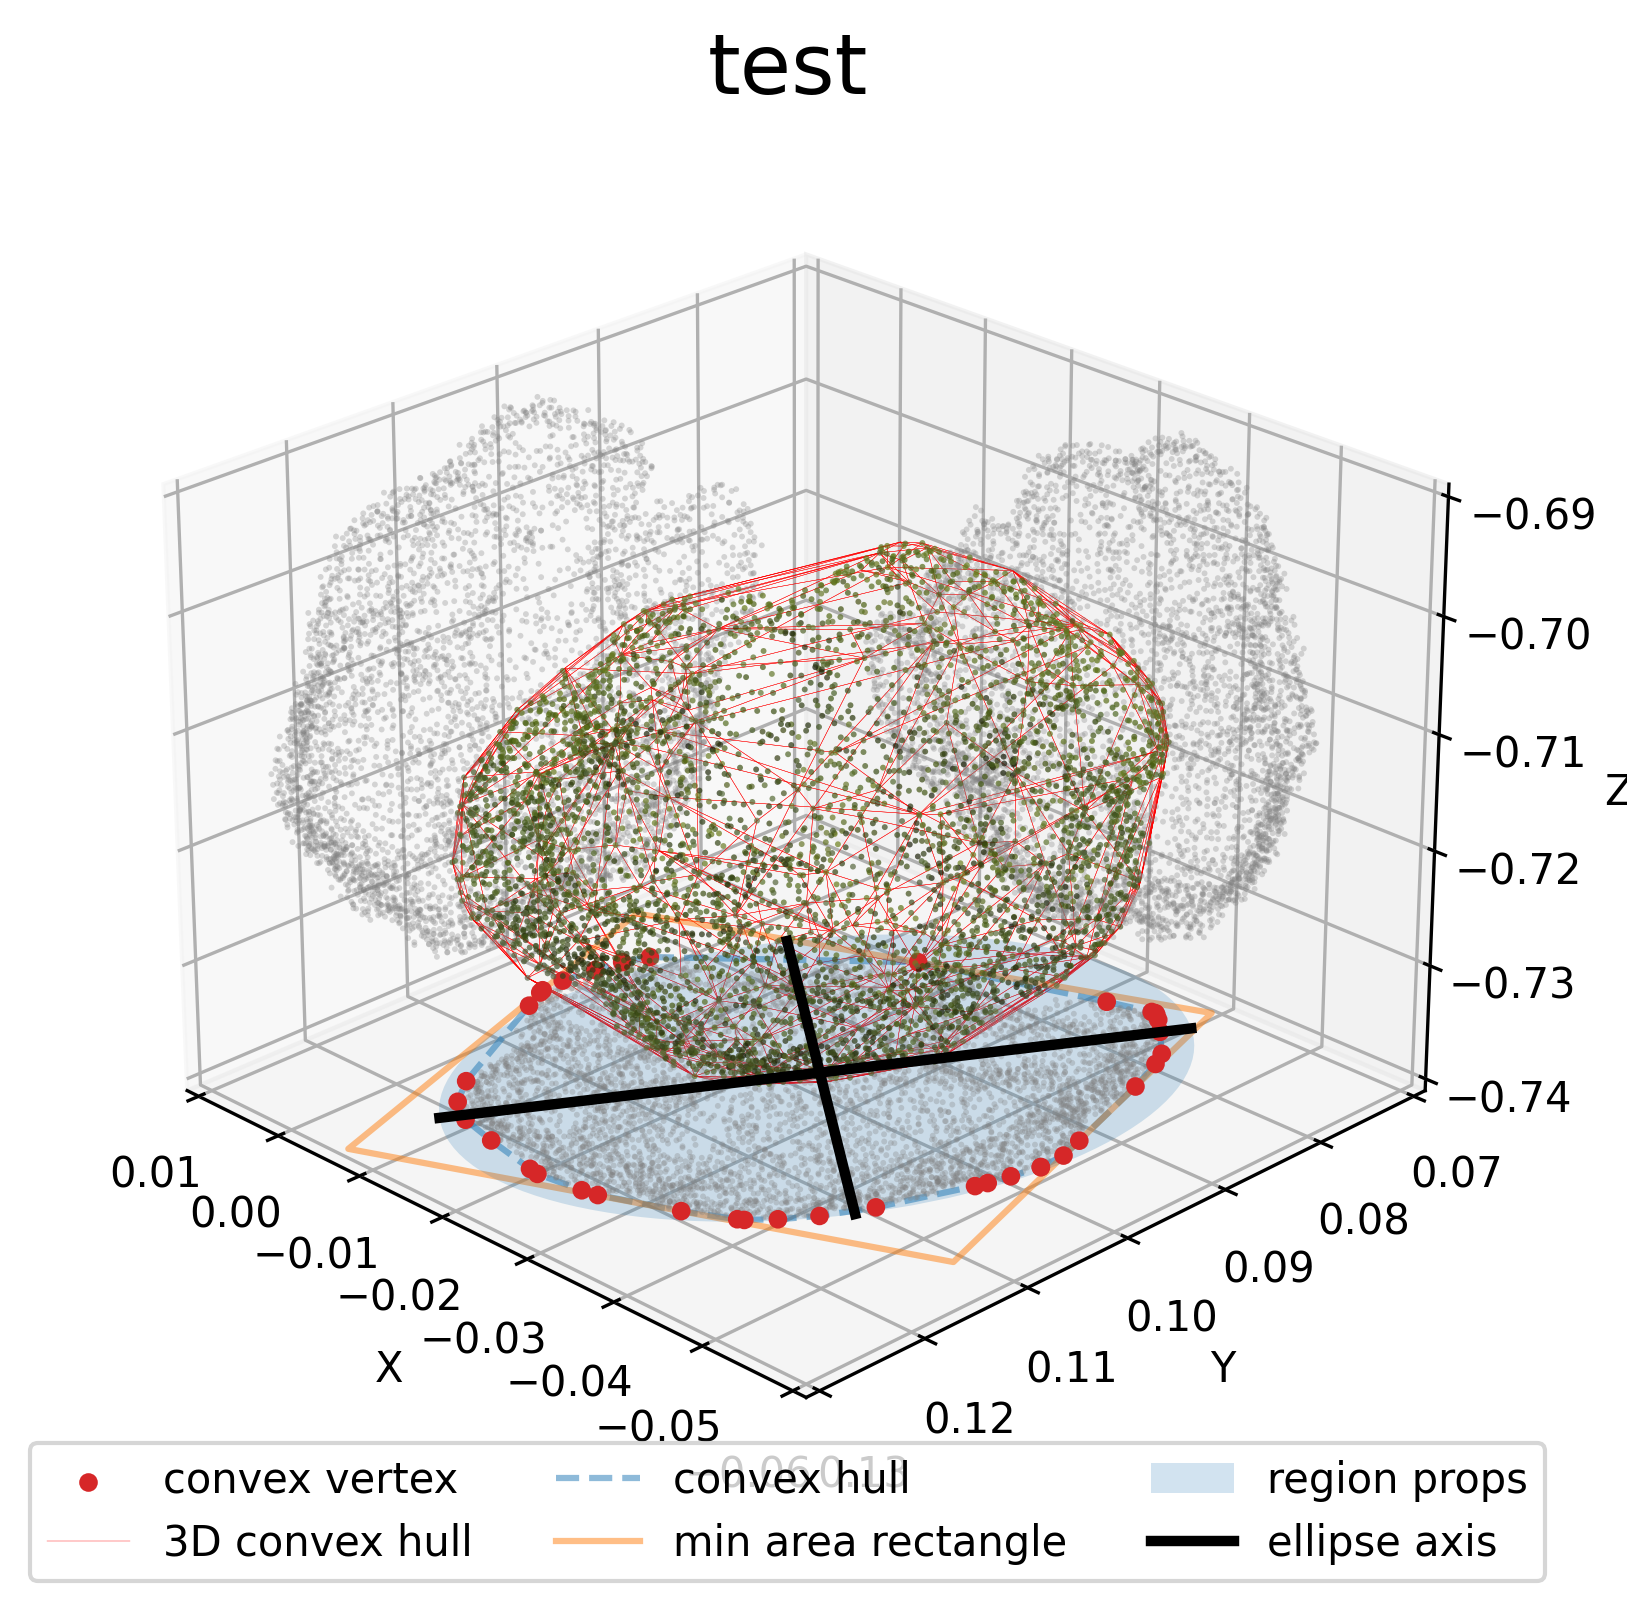

In [99]:
draw_3d_results(plant, 'test', down_voxel_size=0.001, savepath="./traits_show.png")

In [72]:
hull = plant.convex_hull3d
hull

In [73]:
hull.vertices

array([   5,    8,   11,   27,   28,   37,   41,   68,   86,  112,  114,
        119,  122,  124,  136,  143,  159,  160,  164,  170,  172,  179,
        181,  185,  191,  200,  205,  209,  216,  218,  236,  238,  277,
        294,  359,  405,  414,  424,  449,  451,  499,  505,  511,  529,
        532,  551,  567,  646,  717,  725,  750,  764,  770,  772,  777,
        782,  786,  787,  793,  800,  816,  819,  824,  867,  890,  905,
        936,  937,  944,  945,  948,  949,  950,  956,  957,  967,  973,
        983, 1017, 1147, 1179, 1186, 1188, 1189, 1207, 1208, 1212, 1253,
       1258, 1326, 1327, 1341, 1345, 1371, 1374, 1382, 1440, 1486, 1493,
       1500, 1508, 1509, 1523, 1533, 1551, 1554, 1576, 1596, 1603, 1612,
       1613, 1642, 1647, 1676, 1703, 1722, 1738, 1763, 1764, 1765, 1827,
       1836, 1909, 1910, 1913, 1922, 1937, 1977, 2016, 2040, 2057, 2066,
       2080, 2100, 2103, 2104, 2110, 2135, 2145, 2210, 2269, 2280, 2287,
       2289, 2294, 2313, 2314, 2320, 2336, 2357, 23

In [74]:
hull.simplices

array([[ 819, 4017,  983],
       [ 819, 1017,  983],
       [ 218,  200, 4017],
       ...,
       [3372, 3311, 3312],
       [3372, 3347, 3312],
       [3372, 3371, 3347]], dtype=int32)

In [90]:
plant_full = Broccoli(rotated_pcd, 'test')

<ipython-input-89-c84732ce44b1>:109: MatplotlibDeprecationWarning: Passing the angle parameter of __init__() positionally is deprecated since Matplotlib 3.6; the parameter will become keyword-only two minor releases later.
  ell = Ellipse((x0, y0), plant.major_axis, plant.minor_axis, phi,


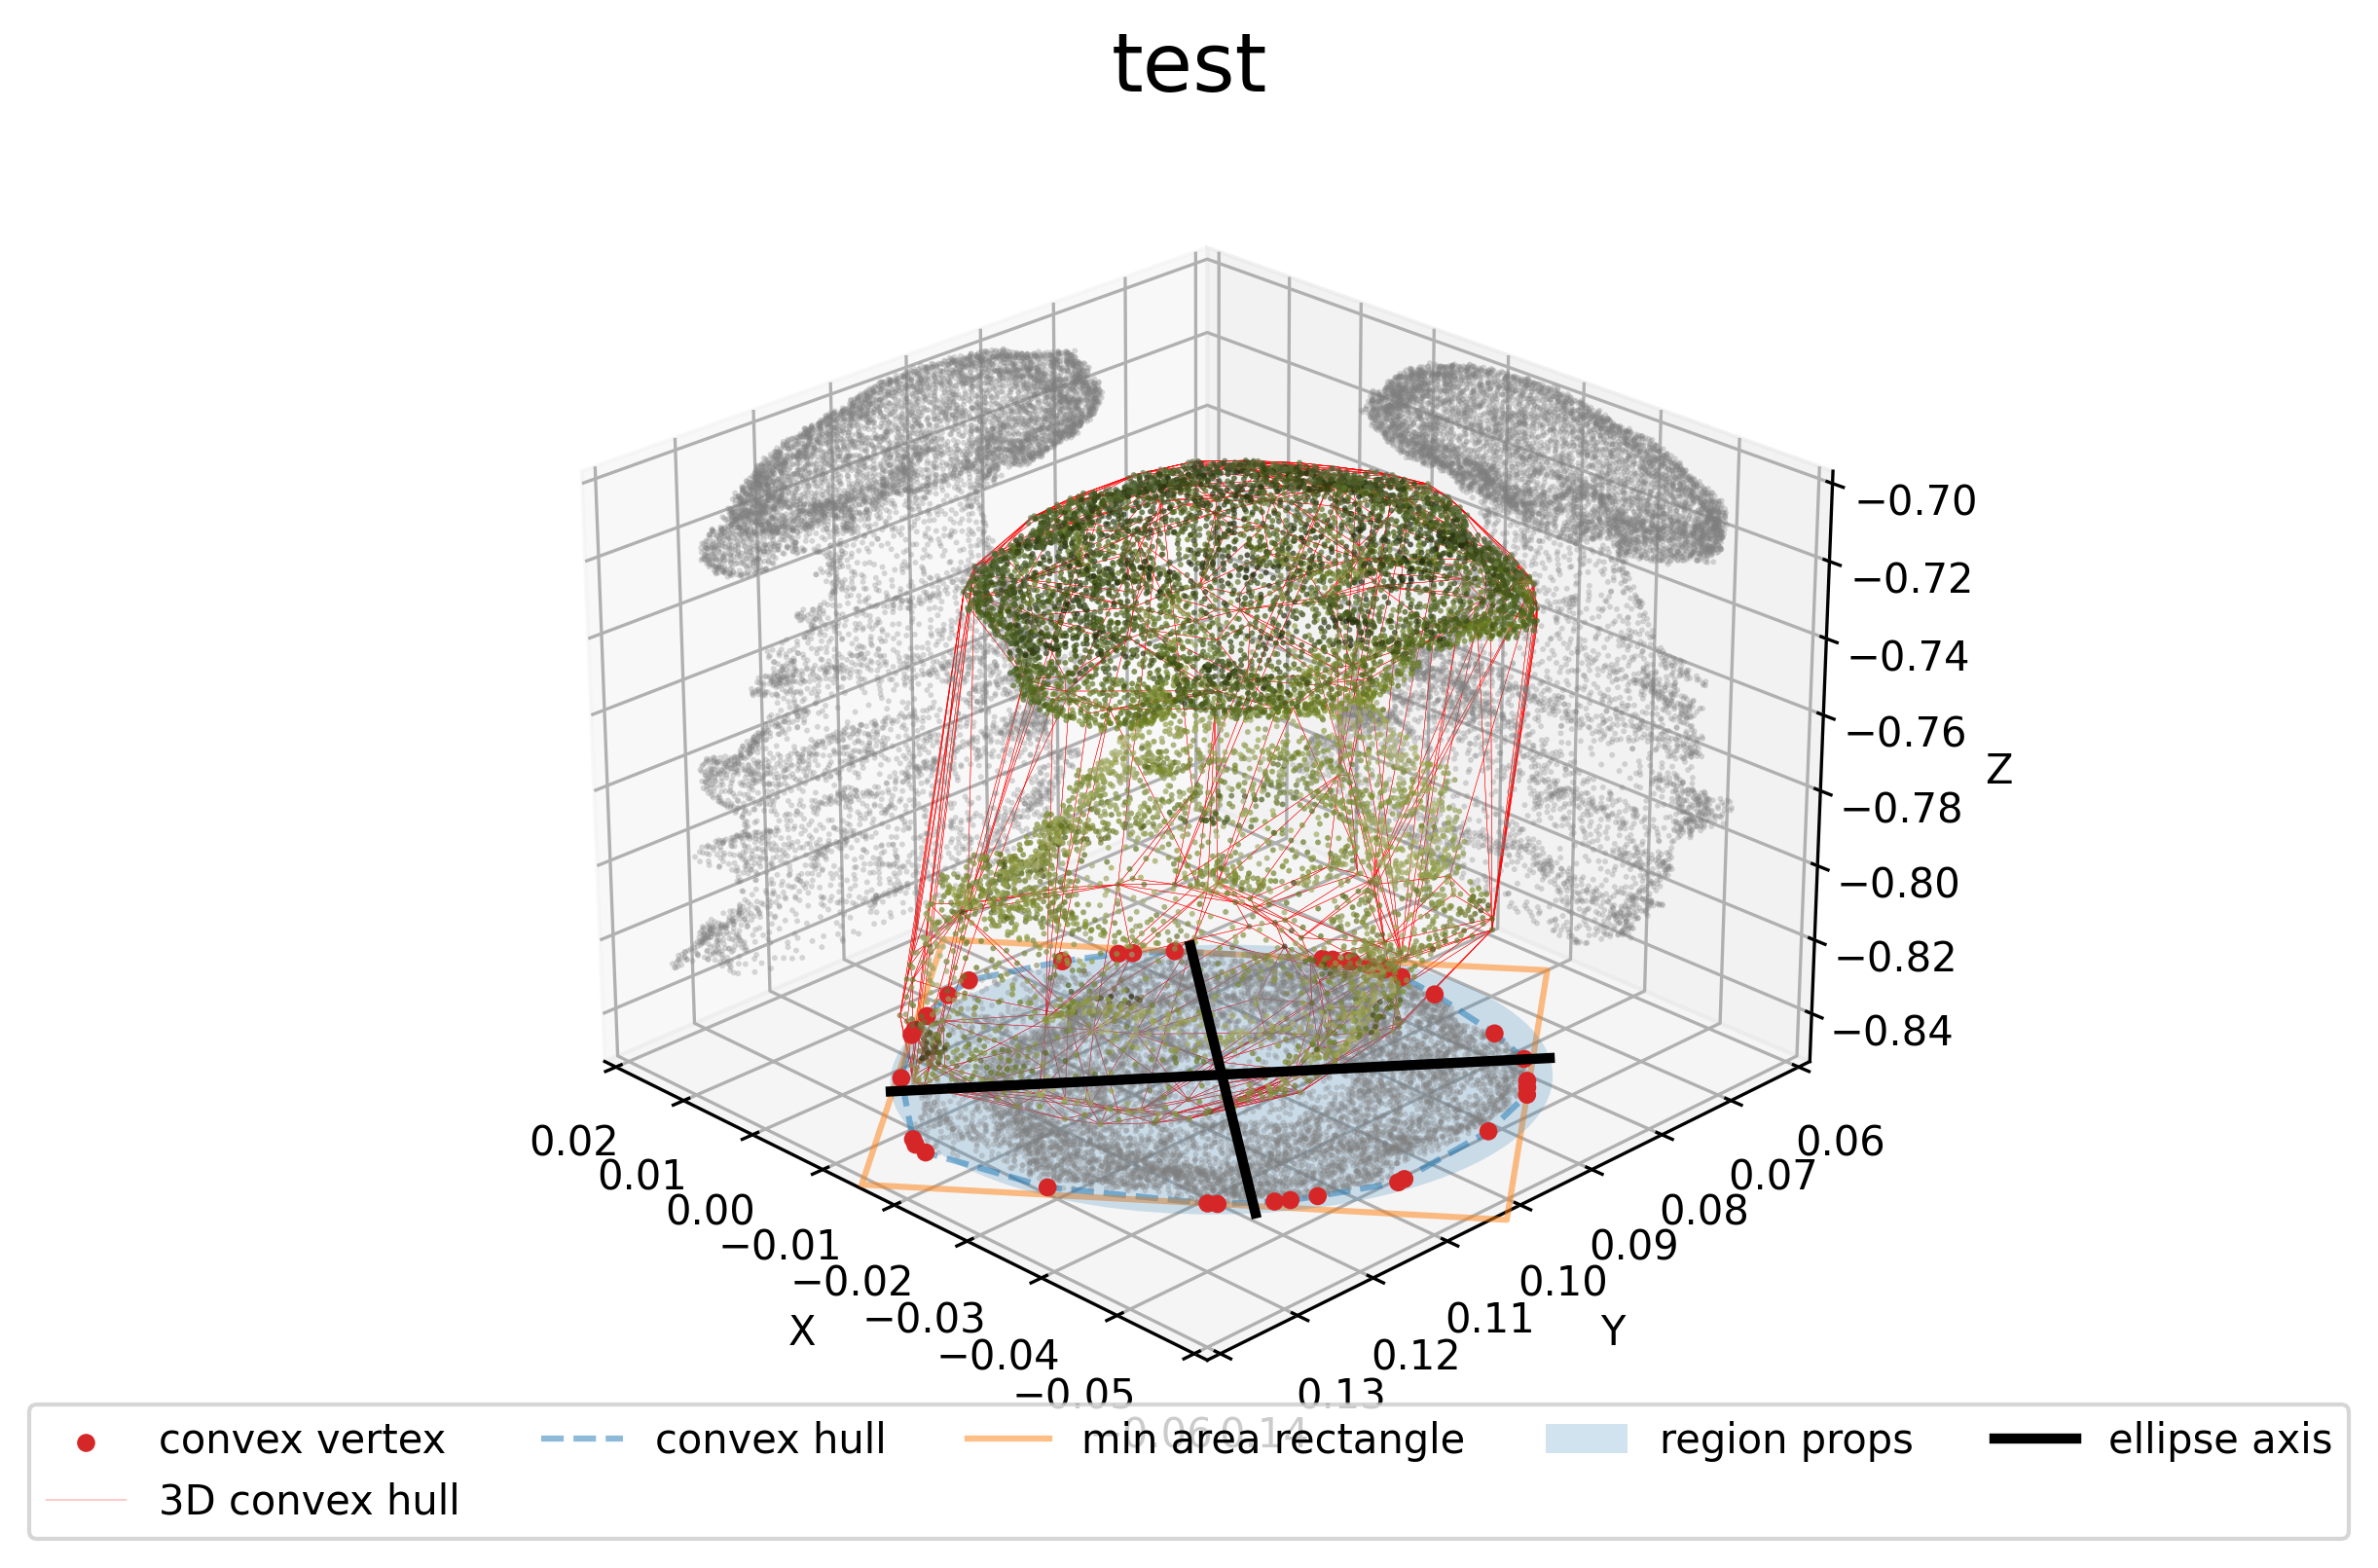

In [91]:
draw_3d_results(plant_full, 'test', down_voxel_size=0.001)

In [95]:
np.asarray(plant_full.concave_hull3d.vertices)

array([[-0.02241565,  0.07503049, -0.72474056],
       [-0.02740137,  0.0754972 , -0.72621113],
       [-0.01704731,  0.07726827, -0.79703206],
       ...,
       [-0.04469464,  0.11741736, -0.76925266],
       [-0.04224503,  0.12104803, -0.72472578],
       [-0.04089904,  0.12156928, -0.72309709]])

In [96]:
np.asarray(plant_full.concave_hull3d.triangles)

array([[   5,    6,    7],
       [   8,    9,   11],
       [  15,   13,   12],
       ...,
       [1307, 1304, 1108],
       [1307, 1108, 1050],
       [1050, 1304, 1307]], dtype=int32)

# save to traits

In [108]:
out_dict = {
    'id': [],
    # crown parameter
    'crown_height(m)': [],
    'center.x(m)': [], 'center.y(m)': [],
    'min_rect_width(m)': [], 'min_rect_length(m)': [], 
    'crown_2dconvex_area(cm2)': [], 'projected_leaf_area(cm2)': [],
    'centroid.x(m)': [], 'centroid.y(m)': [], 
    'long_axis(m)': [], 'short_axis(m)': [], 'orientation(degree)': [], 
    'crown_3dconvex_volume(cm3)':[], 
    'crown_3dconcave_volume(cm3)':[],
    'crown_3dconcave_alpha':[],
    # head parameter
    'head_height(m)': [],
    'head_3dconcave_volume(cm3)':[],
    'head_3dconcave_alpha':[]
}

In [109]:
broccoli_id = '3-4'

bro_mesh = o3d.io.read_triangle_mesh(mesh_db[broccoli_id])

def_test_pcd = mesh2pcd(bro_mesh)

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, vz)

crown_traits = Broccoli(crown_pcd, broccoli_id)
head_traits = Broccoli(rotated_pcd, broccoli_id)

out_dict['id'].append(broccoli_id)
# crown_t5raits
out_dict['crown_height(m)'].append(crown_traits.height)
out_dict['center.x(m)'].append(crown_traits.center[0])
out_dict['center.y(m)'].append(crown_traits.center[1])
out_dict['min_rect_width(m)'].append(crown_traits.width)
out_dict['min_rect_length(m)'].append(crown_traits.length)
out_dict['crown_2dconvex_area(cm2)'].append(crown_traits.hull_area * 100 * 100)
out_dict['projected_leaf_area(cm2)'].append(crown_traits.pla)
out_dict['centroid.x(m)'].append(crown_traits.centroid[0])
out_dict['centroid.y(m)'].append(crown_traits.centroid[1])
out_dict['long_axis(m)'].append(crown_traits.major_axis)
out_dict['short_axis(m)'].append(crown_traits.minor_axis)
out_dict['orientation(degree)'].append(crown_traits.orient_degree)
out_dict['crown_3dconvex_volume(cm3)'].append(crown_traits.hull3d_volume * 1000 * 1000)
out_dict['crown_3dconcave_volume(cm3)'].append(crown_traits.concave_hull3d_volume * 1000 * 1000)
out_dict['crown_3dconcave_alpha'].append(crown_traits.alpha)

# head_traits
out_dict['head_height(m)'].append(head_traits.height)
out_dict['head_3dconcave_volume(cm3)'].append(head_traits.concave_hull3d_volume * 1000 * 1000)
out_dict['head_3dconcave_alpha'].append(head_traits.alpha)

In [110]:
out_dict

{'id': ['3-4'],
 'crown_height(m)': [0.04695999622344971],
 'center.x(m)': [-0.026551148711390495],
 'center.y(m)': [0.10180773880785587],
 'min_rect_width(m)': [0.051632477545065794],
 'min_rect_length(m)': [0.04313257069649294],
 'crown_2dconvex_area(cm2)': [18.2090764922852],
 'projected_leaf_area(cm2)': [21.333333333333332],
 'centroid.x(m)': [-0.024990306678745484],
 'centroid.y(m)': [0.09861161357826656],
 'long_axis(m)': [0.05804382896782109],
 'short_axis(m)': [0.0474596416324206],
 'orientation(degree)': [55.61565652035513],
 'crown_3dconvex_volume(cm3)': [50.21514954841188],
 'crown_3dconcave_volume(cm3)': [194.28292423126746],
 'crown_3dconcave_alpha': [0.02],
 'head_height(m)': [0.14655565737097243],
 'head_3dconcave_volume(cm3)': [194.28292423126746],
 'head_3dconcave_alpha': [0.02]}

# batch processing

In [113]:
out_pd = pd.DataFrame(out_dict)
out_pd

,id,crown_height(m),center.x(m),center.y(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),centroid.x(m),centroid.y(m),long_axis(m),short_axis(m),orientation(degree),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),crown_3dconcave_alpha,head_height(m),head_3dconcave_volume(cm3),head_3dconcave_alpha
0,3-4,0.04696,-0.026551,0.101808,0.051632,0.043133,18.209076,21.333333,-0.02499,0.098612,0.058044,0.04746,55.615657,50.21515,194.282924,0.02,0.146556,194.282924,0.02


In [118]:
out_pd.to_csv('broccoli_traits.csv', index=False)

In [120]:
out_dict = {
    'id': [],
    # crown parameter
    'crown_height(m)': [],
    'center.x(m)': [], 'center.y(m)': [],
    'min_rect_width(m)': [], 'min_rect_length(m)': [], 
    'crown_2dconvex_area(cm2)': [], 'projected_leaf_area(cm2)': [],
    'centroid.x(m)': [], 'centroid.y(m)': [], 
    'long_axis(m)': [], 'short_axis(m)': [], 'orientation(degree)': [], 
    'crown_3dconvex_volume(cm3)':[], 
    'crown_3dconcave_volume(cm3)':[],
    'crown_3dconcave_alpha':[],
    'crown_roundness': [],
    # head parameter
    'head_height(m)': [],
    'head_3dconcave_volume(cm3)':[],
    'head_3dconcave_alpha':[]
}

In [121]:
crown_idx = {}
rotation_matrix = {}
for bro_id, bro_mesh in tqdm(mesh_db.items(), f"Processing Meshs"):
    def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(bro_mesh))

    crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

    crown_idx[bro_id] = crown_points_index

    rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, vz)
    rotation_matrix[bro_id] = R

    crown_traits = Broccoli(crown_pcd, bro_id)
    head_traits = Broccoli(rotated_pcd, bro_id)

    out_dict['id'].append(bro_id)
    # crown_traits
    out_dict['crown_height(m)'].append(crown_traits.height)
    out_dict['center.x(m)'].append(crown_traits.center[0])
    out_dict['center.y(m)'].append(crown_traits.center[1])
    out_dict['min_rect_width(m)'].append(crown_traits.width)
    out_dict['min_rect_length(m)'].append(crown_traits.length)
    out_dict['crown_2dconvex_area(cm2)'].append(crown_traits.hull_area * 100 * 100)
    out_dict['projected_leaf_area(cm2)'].append(crown_traits.pla)
    out_dict['centroid.x(m)'].append(crown_traits.centroid[0])
    out_dict['centroid.y(m)'].append(crown_traits.centroid[1])
    out_dict['long_axis(m)'].append(crown_traits.major_axis)
    out_dict['short_axis(m)'].append(crown_traits.minor_axis)
    out_dict['orientation(degree)'].append(crown_traits.orient_degree)
    out_dict['crown_roundness'].append(crown_traits.roundness)

    out_dict['crown_3dconvex_volume(cm3)'].append(crown_traits.hull3d_volume * 1000 * 1000)
    out_dict['crown_3dconcave_volume(cm3)'].append(crown_traits.concave_hull3d_volume * 1000 * 1000)
    out_dict['crown_3dconcave_alpha'].append(crown_traits.alpha)

    # head_traits
    out_dict['head_height(m)'].append(head_traits.height)
    out_dict['head_3dconcave_volume(cm3)'].append(head_traits.concave_hull3d_volume * 1000 * 1000)
    out_dict['head_3dconcave_alpha'].append(head_traits.alpha)

Processing Meshs: 100%|██████████| 193/193 [39:34<00:00, 12.30s/it]


In [123]:
import easyidp as idp

In [124]:
idp.jsonfile.dict2json(crown_idx, "out/crown_index.json")
idp.jsonfile.dict2json(rotation_matrix, "out/rotation_matrix.json")


In [125]:
out_dict['id'] = list( mesh_db.keys() )

In [126]:
out_pd = pd.DataFrame(out_dict)
out_pd.to_csv('broccoli_traits.csv', index=False)